In [1]:
%matplotlib inline

import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "common").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch
import triton

import cute_vector_add
import triton_vector_add
from common.asm import dump_asm
from common.inputs import make_inputs
from common.run import make_runner, run_benchmark
from neuroslop.visualize_bench_results import plot_benchmark

N = 1 << 24

In [2]:
AUTOTUNE = True  # False runs each kernel with its own defaults

TRITON_KERNEL = triton_vector_add.vector_add_kernel(autotune=AUTOTUNE)

IMPLEMENTATIONS = {
    "torch": make_runner("torch", torch.add),
    "torch_compile": make_runner("torch_compile", lambda x, y: x + y),
    "triton": make_runner(
        "triton",
        TRITON_KERNEL,
        extra_args=lambda a, b, out: (a.numel(),),
        grid=lambda meta: (triton.cdiv(meta["n"], meta["BLOCK_SIZE"]),),
    ),
    "cute": make_runner("cute", cute_vector_add.add(autotune=AUTOTUNE)),
    "cuda": make_runner("cuda", "cuda_vector_add.cu", entry="add"),
}

In [3]:
# Tests: sizes around the block boundary catch kernels that drop the tail.
for n in [1, 255, 256, 257, 1000, N]:
    inputs = make_inputs((n,), (n,))
    for name, fn in IMPLEMENTATIONS.items():
        torch.testing.assert_close(fn(*inputs), torch.add(*inputs), msg=f"{name}, n={n}")
print("OK")

/home/fvelikon/projects/ysda-dsl-benches/.venv/lib/python3.12/site-packages/torch/_dynamo/pgo.py:605: UserWarning: dynamo_pgo force disabled by torch.compiler.config.force_disable_caches
  warn_once(


OK


         torch: 41.120 us (p20-p80: 40.960-41.696) | 0.408006 TFLOP/s | 4896.07 GB/s | 1.05x
 torch_compile: 43.168 us (p20-p80: 42.938-43.712) | 0.388649 TFLOP/s | 4663.79 GB/s | 1.00x
        triton: 41.104 us (p20-p80: 40.928-41.574) | 0.408165 TFLOP/s | 4897.98 GB/s | 1.05x
          cute: 41.200 us (p20-p80: 40.922-41.798) | 0.407214 TFLOP/s | 4886.57 GB/s | 1.05x
          cuda: 63.472 us (p20-p80: 62.093-63.904) | 0.264325 TFLOP/s | 3171.90 GB/s | 0.68x


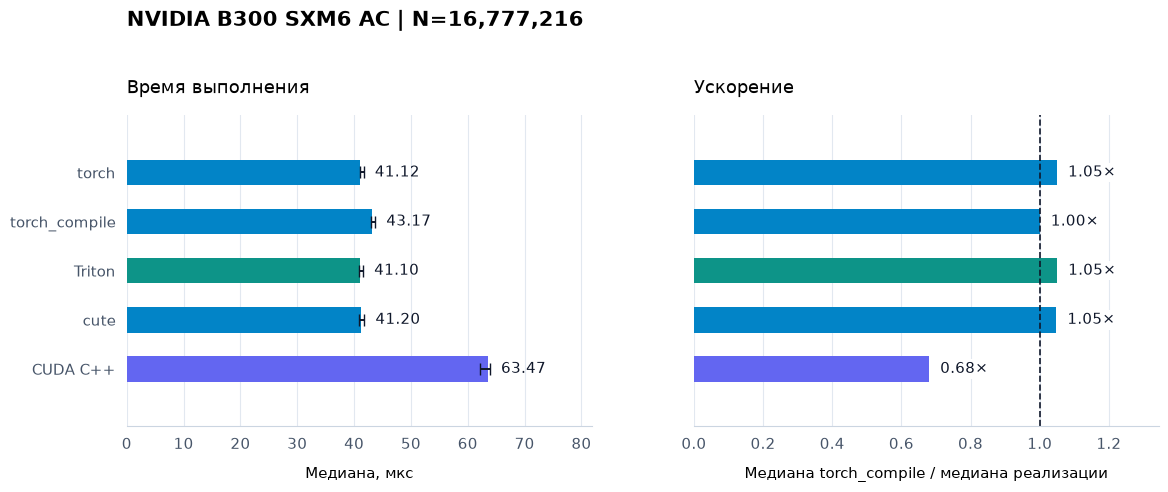

triton config: BLOCK_SIZE: 1024, num_warps: 2, num_ctas: 1, num_stages: 3, maxnreg: None
cute config: {'threads_per_block': 128}


In [4]:
inputs = make_inputs((N,), (N,))
results = run_benchmark(IMPLEMENTATIONS, inputs, reference=torch.add, flops=N)
plot_benchmark(results, baseline="torch_compile", title=f"{torch.cuda.get_device_name()} | N={N:,}")
plt.show()
if AUTOTUNE:
    print("triton config:", TRITON_KERNEL.best_config)
    print("cute config:", IMPLEMENTATIONS["cute"].asm()["add"]["config"])

In [5]:
for name, fn in IMPLEMENTATIONS.items():
    dump_asm(fn.asm(), Path("asm") / name)
    print(name, list(fn.asm()))

torch []


torch_compile ['triton_poi_fused_add_0']
triton ['vector_add_kernel']
cute ['add']
cuda ['cuda_vector_add']
